### Our Research Qestion

##### Are housing prices more influenced by location or property size?

### A) Data Setup 

In [1]:
import pandas as pd 

data_path = "./data/mexico-real-estate-combined-clean.csv"

df = pd.read_csv(data_path)

print(f'Dimensions: {df.shape[0]} rows (m) and {df.shape[1]} columns (n) \n')
print(df.info())
df.head()

Dimensions: 1736 rows (m) and 6 columns (n) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1736 entries, 0 to 1735
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  1736 non-null   object 
 1   state          1159 non-null   object 
 2   lat            1736 non-null   float64
 3   lon            1736 non-null   float64
 4   area_m2        1736 non-null   float64
 5   price_usd      1736 non-null   float64
dtypes: float64(4), object(2)
memory usage: 81.5+ KB
None


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


### B) Histograms 

A histogram divides the range of a numerical variable into **bins** (equal-width
intervals) and counts how many observations fall into each bin. The height of each
bar is the count (frequency) for that bin. The bars touch (unlike bar charts) to
signal that the variable is *continuous* — there are no gaps in the data range.

**What a histogram reveals:**

- **Central tendency** — where most values cluster
- **Spread** — how wide the distribution is
- **Skewness** — whether the distribution has a long tail on one side
- **Modality** — whether there is one peak (unimodal) or multiple peaks (bimodal)
- **Outliers** — isolated bars far from the main cluster

**Bins** — the number of bars — is a user-controlled parameter. Too few bins and
the histogram is over-smoothed (loses detail). Too many bins and it is too jagged
(over-fits the noise). The default (usually 10) is often a good starting point;
adjust based on what the plot is communicating.


create a histogram for `price_usd`

count      1736.000000
mean     117436.962442
std       66673.456313
min       33192.480000
25%       66468.430000
50%      100946.980000
75%      154911.430000
max      338888.888889
Name: price_usd, dtype: float64

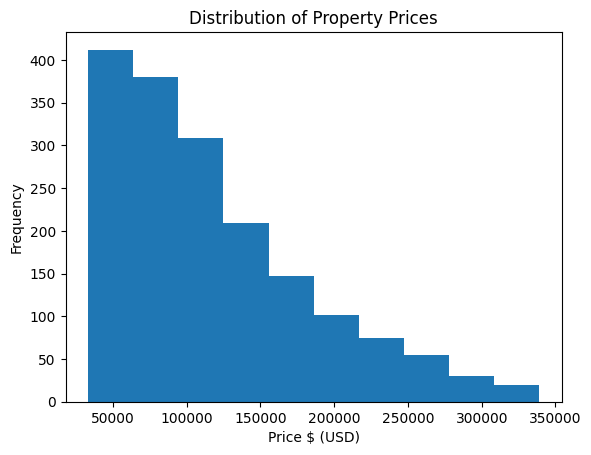

In [2]:
import matplotlib.pyplot as plt 

fig, ax = plt.subplots() #returns a tuple of (figure - the display, Axes - y and x)

ax.hist(df["price_usd"])

ax.set_xlabel("Price $ (USD)")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Property Prices"); # -> colon added to limit the output to just the graph without the system text at the bottom

# the difference from the implicit interface is that we can set the xlim (horizontal range) and ylim (vertical range) using set_
# that is another main difference from the implicit interface (plt.) is that we can set_ 

# i.e. if we set the fig parameters fig, ax = plt.subplots(figsize = (10, 6)) #width = 10 inches and height = 6 inches [ figsize - controls canvas size]

df["price_usd"].describe()

**Statistical Conclusion:**

1. Strong right skew - most properties are priced between USD30 000 and USD130 000
   - the tail tells the tale" -> a small no. of the expensive properties (300 000+) are pulling the mean above the median.
   - *the norm in housing markets* - natural lower bound (mode < median < mean) which makes sense as an expensive property can be x100 median
        - asymmetry (not evenly distributed) of data garuntees this
2. Median is roughly in the 50th percentile around USD95 000
3. Mean sits rougly at USD115 000
4. The gap between the mean and the median is the price of ignoring skewness -> incorrectly interpreting that the prices are actually around USD115 000 on ave.
5. $\therefore$ we will use the median to make statistical conclusions regarding the typical prices across states (vs. using mean)
   - better measure of central tenda

In [3]:
# We then call a quick descreptive statistics summary to confirm 
df["price_usd"].describe()

count      1736.000000
mean     117436.962442
std       66673.456313
min       33192.480000
25%       66468.430000
50%      100946.980000
75%      154911.430000
max      338888.888889
Name: price_usd, dtype: float64

Histogram of `area_m2`

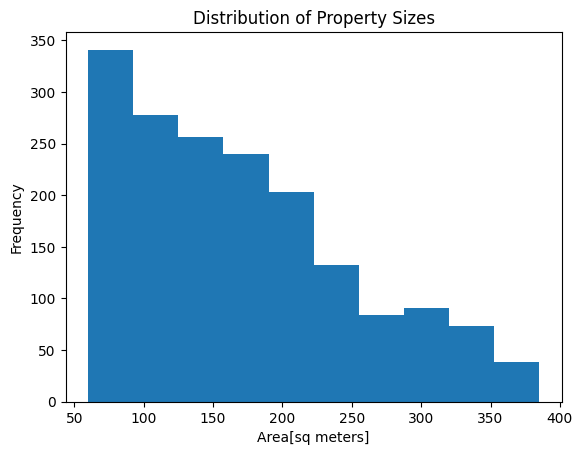

In [4]:
# Create a histogram of area_m2 

fig, ax = plt.subplots()
ax.hist(df["area_m2"])

ax.set_xlabel("Area[sq meters]")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Property Sizes");

**Statistical Conclusion**

1. We can also conclude that property sizes are right-skewed meaning that the dataset contains mostly apartments and smaller houses
2. The long tail - Large Estates:### Bivariate Analysis: Categorical vs. Numerical

We will now study the relationship of two variables together:
* Compare **Numerical Variables** (`price_usd`) vs. **Categorical Variables**
 contains larger properties such as mansions, unbuilt properties with big foundations,  and commercial listings that somehow made it into the dataset
   - we will have to exclude outliers from the dataset as these will dominate the relationship in the SSR and missplace the OLS estimate 

In [5]:
# We then call a quick descreptive statistics summary to confirm 
df["area_m2"].describe()

count    1736.000000
mean      170.261521
std        80.594539
min        60.000000
25%       101.750000
50%       156.000000
75%       220.000000
max       385.000000
Name: area_m2, dtype: float64

### C) Bivariate Analysis: Categorical vs. Numerical

We will now study the relationship of two variables together:
- Compare **Numerical Variables** (`price_usd`) vs. **Categorical Variables** (`state`, `property_type`)
```python
vert = False
``` 
- This rotates the box plot so that the $\mathbb{R}$ runs along the x-axis 

<div class = "alert alert-block alert-success"> 
<b>BOXPLOT</b> 
</div>
   

 ```
     |          ┌────────┬────────┐          |   •  •
     ───────────┤        │        ├──────────────
     |          └────────┴────────┘          |
     ↑          ↑        ↑        ↑          ↑   ↑
    Min        Q1      Median    Q3         Max Outliers
  (or fence)                              (or fence)
 ```
 > $IQR$ = $Q_3 - Q_1$       
 > lower fence (min) = $Q_1$ - 1.5x IQR    
 > upper fence (max) = $Q_3$ + 1.5x IQR   
  
 A boxplot summarises the histogram and is a visualisation of of that summmary with 5 numbers. 

So now we create a boxplot for `price_usd` (numerical) based on `property_type` (qualitative) from the OG DataFrame

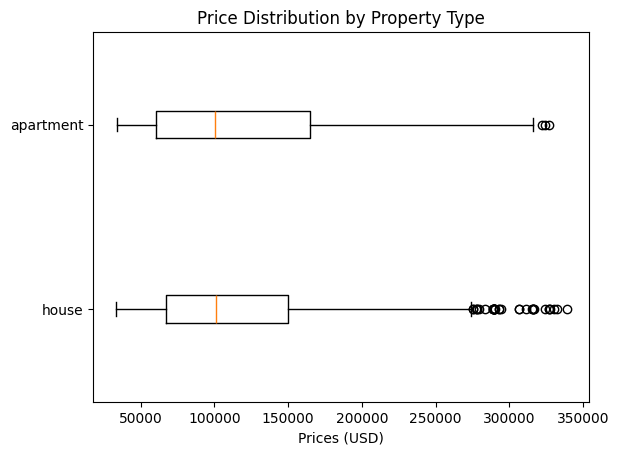

In [6]:
# STEP 1) Get Unique Category Names (no repetition)
prop_types = df["property_type"].unique()

# STEP 2) Prepare the data: Create a list of price arrays for each category of property type 
data_by_type = [df[df["property_type"] == label]["price_usd"] for label in prop_types]

# STEP 3) Plot 
fig, ax = plt.subplots()

# STEP 4) Pass the data list and the label list 
ax.boxplot(data_by_type, tick_labels = prop_types, vert = False)

ax.set_title("Price Distribution by Property Type")
ax.set_xlabel("Prices (USD)")

# STEP 5) Show the graph - voila!
plt.show()

Next we create a similar box plot for the `price_usd` of the 3 most frequent `states` (qualitative)

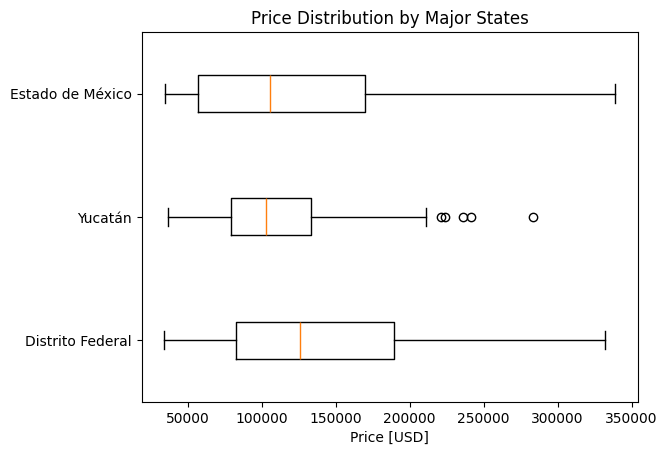

In [7]:
# STEP 1) Define the selected states

selected_states = (
    df["state"]
    .value_counts() # counts all the values in the series df["state"] and arranges them by frequency 
    .head(3) # returns the first 3 cells of the series 
    .index.tolist() # creates a list with those top 3 states 
)

# STEP 2) Prepare the data - all the different prices (USD) for the states sorted by the 3 most occuring in the data only 
data_by_state = [df[df["state"] == state]["price_usd"] for state in selected_states]

# STEP 3) Plotttt twist 

fig, ax = plt.subplots()

ax.boxplot(data_by_state, tick_labels = selected_states, vert = False)

ax.set_title("Price Distribution by Major States")
ax.set_xlabel("Price [USD]")

plt.show()

### D) Bivariate Analysis: Numerical vs Numerical 

We will now study the relationship of two variables together:
- Compare **Numerical Variables** (`price_usd`) vs. **Numerical Variables** (`state`, `property_type`)

<div class = "alert alert-block alert-success"><b>SCATTERPLOT</b></div>

Two *two numerical values* against each other - we compare based on regression and correlation

A scatterplot of `area_m2` and `price_usd`

Text(0, 0.5, 'Price (USD)')

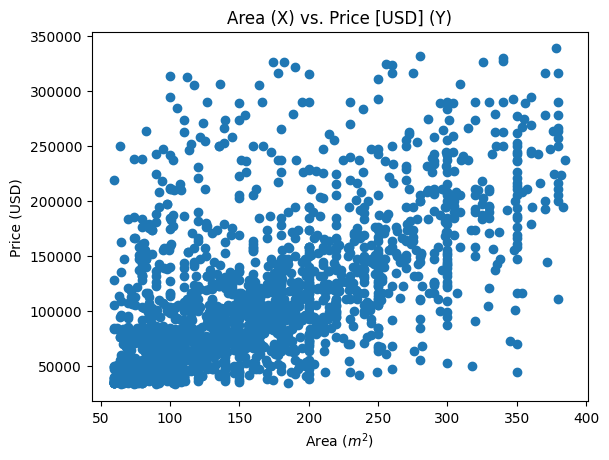

In [8]:
fig, ax = plt.subplots()

ax.scatter(x = df["area_m2"], y = df["price_usd"]) # price is most likely to influence the area size of a property hench area is dependent on price

ax.set_title("Area (X) vs. Price [USD] (Y)")
ax.set_xlabel("Area ($m^{2}$)")
ax.set_ylabel("Price (USD)")

#### Quantile Bassed Outlier Removal 

**The problem:** A handful of extreme properties — an unusually large plot, a top-of-market penthouse — compress the scatterplot, so the pattern for the other 90% of listings becomes harder to read. Beyond visualization, outliers cause mathematical problems: any linear regression line will be pulled toward the extremes, misrepresenting the typical market.

**Why not a fixed cutoff?** Removing properties above $250,000 might work for this dataset — but what about the next dataset, where the price range is different?    

**The solution = quantile-based cutoff** adapts to the data: the 90th percentile is always "the value above which 10% of observations lie," regardless of whether prices are in USD, MXN, or EUR, or whether the dataset has 100 rows or 100,000 rows.

In [9]:
# the value exactly where the top 10% of the dataset is encapsulated 
print(f'The value exactly at the top 10%: {df["price_usd"].quantile(0.9)}')

# the value exactly where the bottom 5% of the dataset is encapsulated (indication of erroneously recorded property listings or unusually cheap property) 
print(f'The value exactly at the bottom 5%: {df["price_usd"].quantile(0.05)}')

The value exactly at the top 10%: 217388.88888888888
The value exactly at the bottom 5%: 39232.060000000005


Then we inspect the 5th percentile to see what unusually cheap property values are contained in the lower bound

In [10]:
properties_5th_percentile = df[df["price_usd"] <= df["price_usd"].quantile(0.05)]
properties_90th_percentile = df[df["price_usd"] >= df["price_usd"].quantile(0.90)]

print(properties_5th_percentile[["price_usd"]])
print(properties_90th_percentile[["price_usd"]])

      price_usd
18     36775.16
68     34254.33
70     35563.37
80     34254.33
112    34599.16
...         ...
1637   33192.48
1694   36090.24
1698   35299.94
1710   37934.26
1726   36260.68

[87 rows x 1 columns]
      price_usd
5     274034.68
16    264390.77
22    262905.55
42    247626.47
52    237089.17
...         ...
1676  229240.55
1702  289775.66
1709  252895.12
1717  316118.90
1734  245050.24

[174 rows x 1 columns]


out of 1736 properties 87 lie in the bottom 5% and 174 lie above the 90th percentile
- this is not a massize loss of data so we can proceed to use 5% as our lower removal and 90th percentile as our upper removal
    - remember that these are all extreme values that are going to mathematically distort the linearity of two variables $\Rightarrow$ would not show the closest true est of the influence of one on the other (r $\equiv$ correlation)

Original: 1736 rows
Cleaned: 1365 rows
Removed: 371 rows


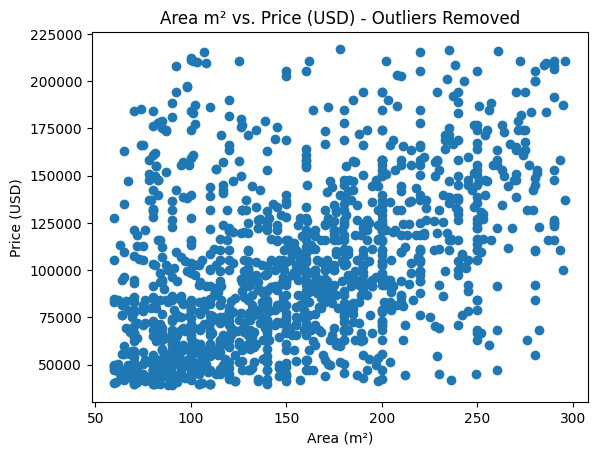

In [11]:
# STEP 1) Define the Cutt-off Percentage
lower_cut = 0.05
upper_cut = 0.90 

# STEP 2) filter the data - keeping the data contained in the 85% range defined in this interval 
df_clean = (
    df[
        (df["price_usd"] > df["price_usd"].quantile(lower_cut)) &
        (df["price_usd"] < df["price_usd"].quantile(upper_cut)) &
        (df["area_m2"] < df["area_m2"].quantile(upper_cut)) # large area outliers also skew the scatter plot
    ]
)

# STEP 3) show what changed 
print(f'Original: {len(df)} rows')
print(f'Cleaned: {len(df_clean)} rows')
print(f'Removed: {len(df) - len(df_clean)} rows')

# STEP 4) Plotttt twist 
fig, ax = plt.subplots() # In God's grace you are not lost - you are lead by the spirit 

ax.scatter(df_clean["area_m2"], df_clean["price_usd"])
ax.set_title("Area m\u00b2 vs. Price (USD) - Outliers Removed")
ax.set_xlabel("Area (m\u00b2)")
ax.set_ylabel("Price (USD)")

plt.show()

Now that we have removed implausibly cheap properties and luxury property listing outliers in the lower and upper quartiles respectively - we can say that future regresssion models will learn from the typical market trend rather than the distorted picture that was in `df` from the extreme values. 

The scatter plot now, by saying typical, represents the everyday buyers expereience - remember people who typically inhabit luxury homes in themselves are outliers in the global and mexican perspective of income per capita. 

We also see hetroscedacity and noise that was hidden by the compacting of the data points in the uncleaned data (around 150 $m^{2}$) - this hints to us that indeed `area $m^{2}` does not explain price alone - along with the spread of the datapoints over the whole scatterplot. Hence area alone is insufficient to predict property price. 

<div class = "alert alert-block alert-success"><b>VISUALISATION OF TREND: SEABORN REGPLOT - LINEAR REGGRESSION</b></div>

In [12]:
import seaborn as sns 

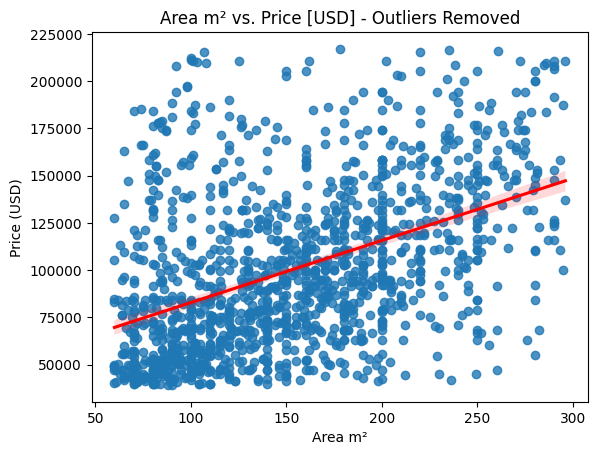

In [13]:
fig, ax = plt.subplots()

sns.regplot(
    data = df_clean, 
    x = "area_m2",
    y = "price_usd",
    line_kws = {"color" : "red"}, # Make the line distinct 
    ax = ax # passing the axis to seaborn
)

ax.set_xlabel("Area m\u00b2")
ax.set_ylabel("Price (USD)")
ax.set_title("Area m\u00b2 vs. Price [USD] - Outliers Removed")

plt.show()

OLS Estimator $\Rightarrow$ $\hat{Y} \space = \space \hat{\alpha} \space + \space X\hat{\beta}$

e can actually use `statsmodels.api` to actually get our OLS components 
- co-efficients  $\Rightarrow$ our y-int ( $\alpha$ ) and slope ( $\beta$ )
- $R^{2}$  $\Rightarrow$  vriability of the points around the trend/OLS
    - $\sqrt{R^{2}} = R =$ Correlation
 
Hypothesis Testing can then be conducted ($H_0 \space vs \space H_1$)
  - p values $\Rightarrow$  standerdised comparison to a significance level of 5% $\rightarrow$ p < 0.05 or p > 0.05
  - ctirtical values ( t vs. $\left| \space t \space \right|$ ) $\Rightarrow$ for t-test using the tables |  $\left| \space t \space \right|$ = $\sqrt{\frac{R^{2}*(n-2)}{1-R^{2}}}$ 2 degrees of freedom removed
  - using confidence interval $\Rightarrow$  generic one in the output is 97.5% confidence level - standard is 95% confidence level 
  - f-statistic  $\Rightarrow$ how well the data fits the model 

In [14]:
import statsmodels.api as sm 

X = sm.add_constant(df_clean["area_m2"]) # big X to show that this is a constant random variable (price is too but we are more concerned with predicting Y when regressing - as the end goal)
y = df_clean["price_usd"]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              price_usd   R-squared:                       0.209
Model:                            OLS   Adj. R-squared:                  0.208
Method:                 Least Squares   F-statistic:                     360.3
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           1.81e-71
Time:                        12:26:02   Log-Likelihood:                -16340.
No. Observations:                1365   AIC:                         3.268e+04
Df Residuals:                    1363   BIC:                         3.270e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       4.995e+04   2847.761     17.540      0.0

$\therefore$    
$\hat{Y} \space = \space \hat{\alpha} \space + \space X\hat{\beta}$   
$\Rightarrow$ $\hat{Y} = \space 17.5778 \space + \space 328.6535X$

$\alpha$ = 4.995e+04 = 17.5778
$\beta$ = 328.6535  
$R^{2}$ = 0.209  
$r$ = 0.4572  
critical value (t) = 18.981  
f stat = 360.3   

we can conclude that the two variables move in the same direction and that 20.9% of the variablity the price in dollars is explained by the variability in area per square meter

<div class = "alert alert-block alert-success"><b>SMALL MULTIPLES - INFLUENCE OF LOCATION</b></div>

To understand the state to state difference in price (USD) per area $m^{2}$ we need to see which states have the highest prices

as 100 $m^{2}$ house does not cost the same in any 2 given states by logical deduction. 

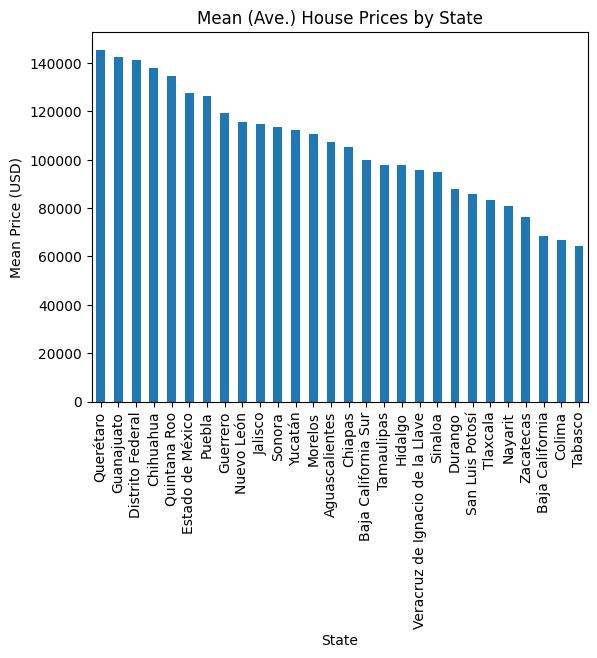

In [15]:
# STEP 1) Aggregate data using group by 

mean_price_by_state = (
    df.groupby("state")["price_usd"] # <-- "state" chained to the "price_usd" relating to that state 
    .mean()
    .sort_values(ascending=False) # mean prices will thus go from high to low in order
)

# STEP 2) Plot Twissttt - Mean Version
# STEP 2.1) Create Figure and Axes explicitly

fig, ax = plt.subplots()

# STEP 2.2) Use pandas plot method with explicit axes 

mean_price_by_state.plot(
    kind = "bar",
    ax=ax # passing the axis to pandas
)

# STEP 2.3) Customise using Matplotlib methods 

ax.set_xlabel("State")
ax.set_ylabel("Mean Price (USD)")
ax.set_title("Mean (Ave.) House Prices by State")

plt.show()

But remember that the mean in the case of this data set does not acurately depict central tendancy due to extreme valuse on the higher end of the tail pushing the mean above the median by a substantial amount

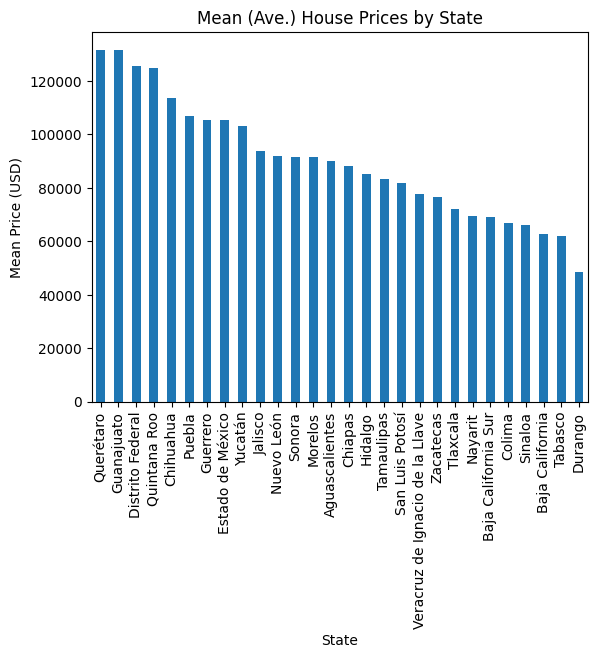

In [16]:
# STEP 1) Aggregate data using group by 

mean_price_by_state = (
    df.groupby("state")["price_usd"] # <-- "state" chained to the "price_usd" relating to that state 
    .median()
    .sort_values(ascending=False) # mean prices will thus go from high to low in order
)

# STEP 2) Plot Twissttt - Mean Version
# STEP 2.1) Create Figure and Axes explicitly

fig, ax = plt.subplots()

# STEP 2.2) Use pandas plot method with explicit axes 

mean_price_by_state.plot(
    kind = "bar",
    ax=ax # passing the axis to pandas
)

# STEP 2.3) Customise using Matplotlib methods 

ax.set_xlabel("State")
ax.set_ylabel("Mean Price (USD)")
ax.set_title("Mean (Ave.) House Prices by State")

plt.show()

Now the median shows the more realistic value of where the price sits at the actual 50% point in the DataFrame per state

<div class = "alert alert-block alert-success"><b>SMALL MULTIPLES - SIZE VS PRICE BY LOCATION</b></div>

Ok so now we can see how the price is distributed along the states on average so what about the effect of the size (area) of a property in a given state? will the relationship with price remain consistent? We use small multiples to zoom into specific sub groups (individual states) and see what the notion is relating to area (are there high prices for smaller property size or are the higher property sizes justified by a larger estate?)

**Definition**

**What are small multiples?**
>
> Small multiples (also called facets or panel charts) are a grid of charts where
> each panel shows the same type of visualization for a different subgroup. The
> axes are aligned across panels so differences in slope, intercept, and scatter
> are immediately visible

**When to use small multiples:**
> - When you have a numerical-numerical relationship (scatterplot) and want to see
>   if it differs across categories (states, property types, years)
> - When a single plot with multiple colors would be too cluttered to read
> - When the comparison across panels is more informative than the individual panels



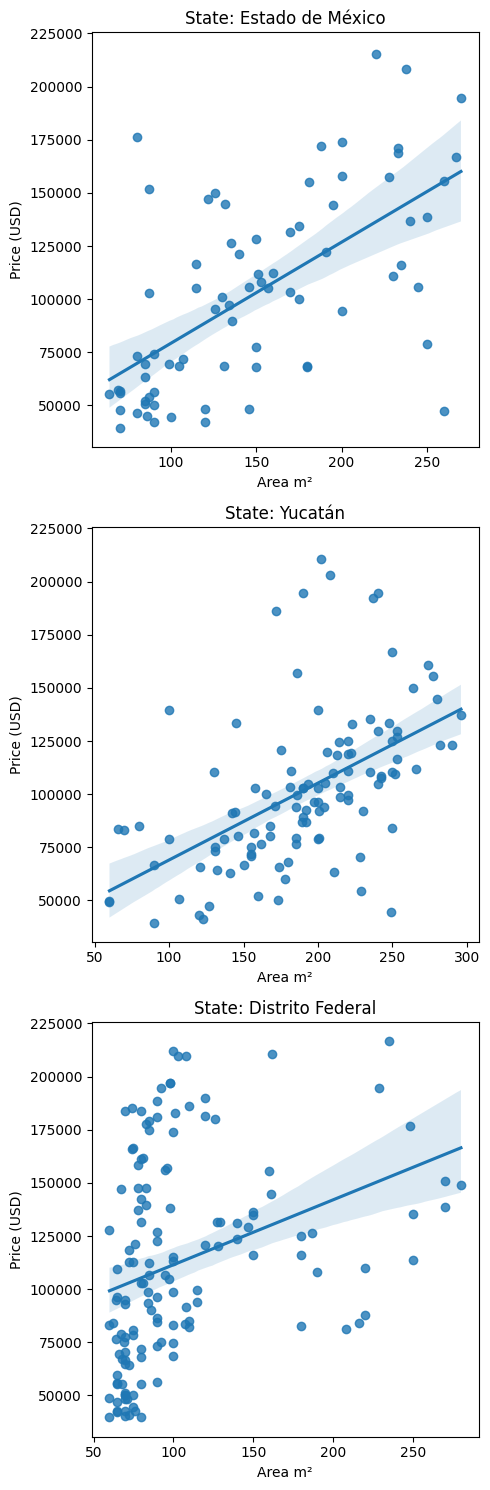

In [17]:
## 1. Create your custom figure and axes
fig, axes = plt.subplots(3, 1, figsize=(5, 15), sharey=True)

# 2. Create a list of the top 3 states
top_states = selected_states   # <--- pass selected_states

# 3. Filter df_clean to include only these states without the effect of extreme values/outliers 
df_states = df_clean[df_clean["state"].isin(top_states)]

# 4. Loop through the states and plot on each specific axis
states = df_states["state"].unique() # Should have 3 states appear 

for ax, state in zip(axes, states):
    # Filter data for the current state
    subset = df_states[df_states["state"] == state]
    
    # Use regplot (Axes-level) which ACCEPTS 'ax='
    sns.regplot(
        data=subset,
        x= "area_m2",  # <--- "area_m2"
        y="price_usd",  # <--- "price_usd" 
        color='tab:blue', # Optional: keep colors consistent
        ax=ax # <--- This is where you pass the axis explicitly
    )
    
    ax.set_title(f"State: {state}")
    ax.set_xlabel("Area m\u00b2")
    ax.set_ylabel("Price (USD)")

plt.tight_layout()
plt.show()

**1) Estado de México — moderate positive relationship:**

- The regression line rises at a clear angle — area does predict price here.
- Wide confidence band — the relationship is real but imprecise. Many properties
  deviate substantially from the line.
- Several high-price properties sit well above the line, suggesting other factors
  (proximity to Mexico City? Specific neighborhoods?) drive premiums.

**2) Yucatán — strongest and most consistent relationship:**

- Narrow confidence band — the regression line is estimated with high precision.
  The relationship between size and price is more predictable here than in the
  other two states.
- Points cluster more tightly around the line.
- Interpretation: in Yucatán, size is a stronger predictor of price than elsewhere.

**3) Distrito Federal — weakest relationship:**

- Notice the **compression on the x-axis** — most properties cluster between
  60–120 m². In Mexico City, land is expensive and apartments dominate, so large
  properties are genuinely rare.
- The regression line is nearly flat, and the confidence band is wide — size
  barely explains price in Distrito Federal.
- Interpretation: in Mexico City, **price depends more on location within the city
  (neighborhood, floor, view, proximity to transit) than on raw size.** A 100 m²
  apartment in Polanco is worth far more than a 100 m² apartment in the periphery.

**The confidence band as a sample-size signal**

Beyond indicating slope uncertainty, the width of the confidence band carries
a second message: it tells you how much data supports the estimate at each
point along the x-axis. Understanding this turns the band from a decorative
shading into a diagnostic tool.

**Why the band widens at the extremes:** The regression line is fitted to all
the data simultaneously, so it is most precisely estimated where the data is
densest. In our three-state plot:
- For Yucatán and Estado de México, most properties cluster between 60–150 m².
  The band is narrowest in this range — many data points are constraining the
  line's position.
- As area increases toward 200–250 m², fewer properties exist. With fewer points
  to anchor the line, the model becomes less certain about where the line should
  sit. The band widens to communicate this uncertainty honestly.
- At the far right edge of each plot, the band may be extremely wide — there
  could be just one or two properties at those sizes. A single property at 300 m²
  can drag the line significantly, but the wide band tells you not to trust that
  estimate.
  